In [1]:
import pandas as pd
import numpy as np

print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

Pandas version: 3.0.6
NumPy version: 2.5.3


In [2]:
df = pd.read_csv("../data/raw/ai4i2020.csv")

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Dataset loaded successfully!
Rows: 10000
Columns: 14


In [3]:
df.columns

Index(['UDI', 'Product ID', 'Type', 'Air temperature [K]',
       'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]',
       'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF',
       'RNF'],
      dtype='str')

In [4]:
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9), str(2)
me

In [6]:
df.describe()

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


In [7]:
df.isnull().sum()

UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

In [8]:
df["Machine failure"].value_counts()

Machine failure
0    9661
1     339
Name: count, dtype: int64

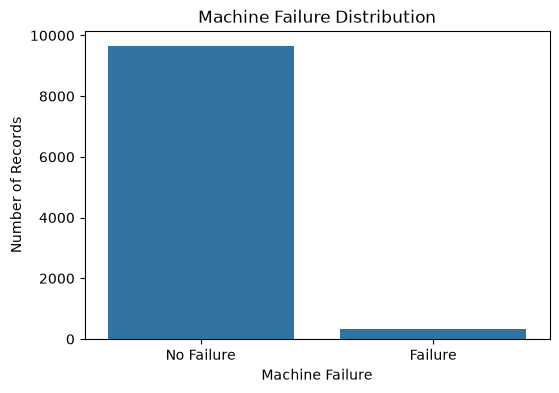

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

failure_counts = df["Machine failure"].value_counts()

plt.figure(figsize=(6, 4))
sns.barplot(
    x=failure_counts.index,
    y=failure_counts.values
)

plt.title("Machine Failure Distribution")
plt.xlabel("Machine Failure")
plt.ylabel("Number of Records")
plt.xticks([0, 1], ["No Failure", "Failure"])
plt.show()

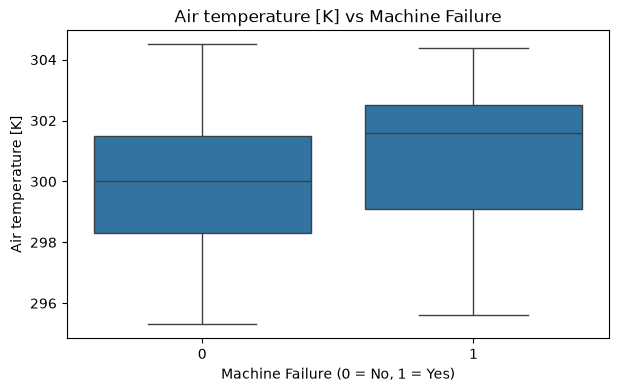

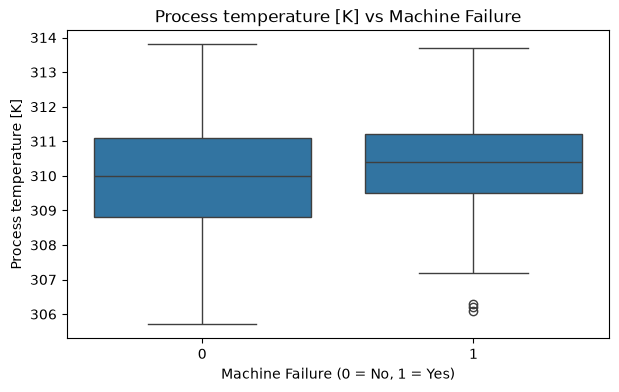

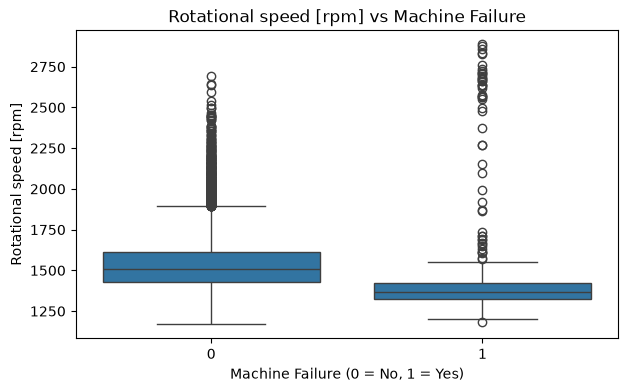

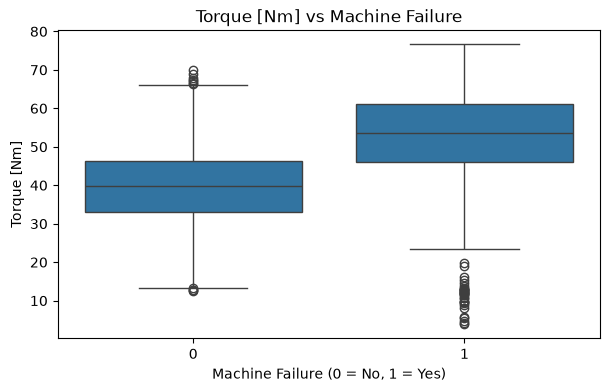

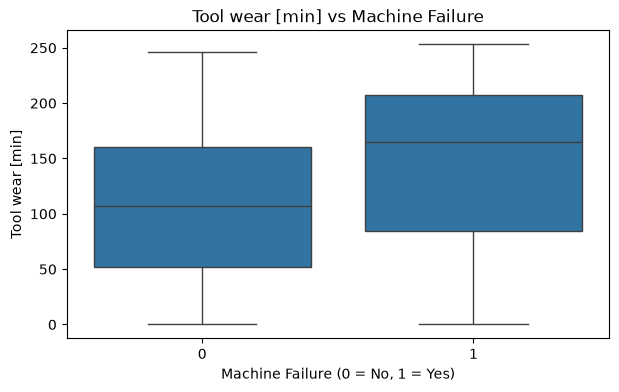

In [10]:
features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

for feature in features:
    plt.figure(figsize=(7, 4))
    sns.boxplot(
        x="Machine failure",
        y=feature,
        data=df
    )

    plt.title(f"{feature} vs Machine Failure")
    plt.xlabel("Machine Failure (0 = No, 1 = Yes)")
    plt.ylabel(feature)
    plt.show()

In [11]:
failure_modes = ["TWF", "HDF", "PWF", "OSF", "RNF"]

df[failure_modes].sum().sort_values(ascending=False)

HDF    115
OSF     98
PWF     95
TWF     46
RNF     19
dtype: int64

In [13]:
failure_modes = ["TWF", "HDF", "PWF", "OSF", "RNF"]

df["Number of Failure Modes"] = df[failure_modes].sum(axis=1)

df["Number of Failure Modes"].value_counts().sort_index()

Number of Failure Modes
0    9652
1     324
2      23
3       1
Name: count, dtype: int64

In [14]:
df[df["Machine failure"] == 1]["Number of Failure Modes"].value_counts().sort_index()

Number of Failure Modes
0      9
1    306
2     23
3      1
Name: count, dtype: int64

In [15]:
for mode in failure_modes:
    total = df[mode].sum()
    failure_rate = total / len(df) * 100
    print(f"{mode}: {total} records ({failure_rate:.2f}%)")

TWF: 46 records (0.46%)
HDF: 115 records (1.15%)
PWF: 95 records (0.95%)
OSF: 98 records (0.98%)
RNF: 19 records (0.19%)


In [16]:
for mode in failure_modes:
    rate = df.loc[df[mode] == 1, "Machine failure"].mean() * 100
    print(f"{mode} -> Machine failure rate: {rate:.2f}%")

TWF -> Machine failure rate: 100.00%
HDF -> Machine failure rate: 100.00%
PWF -> Machine failure rate: 100.00%
OSF -> Machine failure rate: 100.00%
RNF -> Machine failure rate: 5.26%


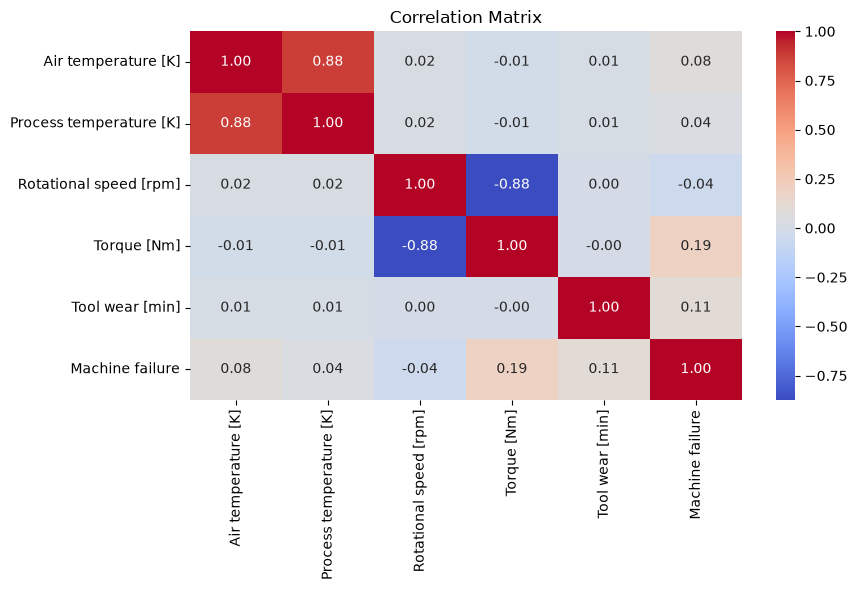

In [17]:
numeric_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
    "Machine failure"
]

plt.figure(figsize=(9, 6))

sns.heatmap(
    df[numeric_features].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

In [24]:
#Feature 1 — Temperature difference

df["Temperature Difference [K]"] = (
    df["Process temperature [K]"] -
    df["Air temperature [K]"]
)

In [25]:
#feature 2 - mechanical power
import numpy as np

df["Mechanical Power [W]"] = (
    df["Torque [Nm]"] *
    df["Rotational speed [rpm]"] *
    (2 * np.pi / 60)
)

In [26]:
#Feature 3 — Tool wear × Torque
df["Tool Wear Torque Interaction"] = (
    df["Tool wear [min]"] *
    df["Torque [Nm]"]
)

In [29]:
df[
    [
        "Temperature Difference [K]",
        "Mechanical Power [W]",
        "Tool Wear Torque Interaction"
    ]
].head()

,Temperature Difference [K],Mechanical Power [W],Tool Wear Torque Interaction
0,10.5,6951.590560,0.0
1,10.5,6826.722724,138.9
2,10.4,7749.387543,247.0
3,10.4,5927.504659,276.5
4,10.5,5897.816608,360.0


In [27]:
type_failure = (
    df.groupby("Type")["Machine failure"]
    .agg(["count", "sum", "mean"])
)

type_failure["failure_rate_%"] = type_failure["mean"] * 100

type_failure

,count,sum,mean,failure_rate_%
Type,,,,
H,1003,21,0.020937,2.093719
L,6000,235,0.039167,3.916667
M,2997,83,0.027694,2.769436


In [28]:
df["Type"].value_counts()

Type
L    6000
M    2997
H    1003
Name: count, dtype: int64

In [30]:
model_features = [
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
    "Temperature Difference [K]",
    "Mechanical Power [W]",
    "Tool Wear Torque Interaction"
]

X = df[model_features].copy()
y = df["Machine failure"].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (10000, 9)
y shape: (10000,)


In [32]:
X.head()

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Temperature Difference [K],Mechanical Power [W],Tool Wear Torque Interaction
0,M,298.1,308.6,1551,42.8,0,10.5,6951.590560,0.0
1,L,298.2,308.7,1408,46.3,3,10.5,6826.722724,138.9
2,L,298.1,308.5,1498,49.4,5,10.4,7749.387543,247.0
3,L,298.2,308.6,1433,39.5,7,10.4,5927.504659,276.5
4,L,298.2,308.7,1408,40.0,9,10.5,5897.816608,360.0


In [33]:
y.value_counts()

Machine failure
0    9661
1     339
Name: count, dtype: int64

In [34]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training set: (8000, 9)
Testing set: (2000, 9)

Training target distribution:
Machine failure
0    7729
1     271
Name: count, dtype: int64

Testing target distribution:
Machine failure
0    1932
1      68
Name: count, dtype: int64


In [35]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

categorical_features = ["Type"]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "type",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ],
    remainder="passthrough"
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Processed training shape: (8000, 11)
Processed testing shape: (2000, 11)


In [36]:
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

logistic_model.fit(X_train_processed, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [37]:
y_pred = logistic_model.predict(X_test_processed)
y_prob = logistic_model.predict_proba(X_test_processed)[:, 1]

print("Predictions generated successfully!")

Predictions generated successfully!


In [38]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

print("Classification Report:")
print(classification_report(y_test, y_pred, digits=4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))

print("PR-AUC:", round(average_precision_score(y_test, y_prob), 4))

Classification Report:
              precision    recall  f1-score   support

           0     0.9952    0.8561    0.9204      1932
           1     0.1775    0.8824    0.2956        68

    accuracy                         0.8570      2000
   macro avg     0.5864    0.8692    0.6080      2000
weighted avg     0.9674    0.8570    0.8992      2000


Confusion Matrix:
[[1654  278]
 [   8   60]]

ROC-AUC: 0.9387
PR-AUC: 0.4413


In [39]:
from sklearn.ensemble import RandomForestClassifier

random_forest_model = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

random_forest_model.fit(X_train_processed, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [40]:
rf_pred = random_forest_model.predict(X_test_processed)
rf_prob = random_forest_model.predict_proba(X_test_processed)[:, 1]

print("Random Forest predictions generated successfully!")

Random Forest predictions generated successfully!


In [41]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

print("Random Forest Classification Report:")
print(classification_report(y_test, rf_pred, digits=4))

print("\nRandom Forest Confusion Matrix:")
print(confusion_matrix(y_test, rf_pred))

print("\nRandom Forest ROC-AUC:",
      round(roc_auc_score(y_test, rf_prob), 4))

print("Random Forest PR-AUC:",
      round(average_precision_score(y_test, rf_prob), 4))

Random Forest Classification Report:
              precision    recall  f1-score   support

           0     0.9938    0.9984    0.9961      1932
           1     0.9492    0.8235    0.8819        68

    accuracy                         0.9925      2000
   macro avg     0.9715    0.9110    0.9390      2000
weighted avg     0.9923    0.9925    0.9922      2000


Random Forest Confusion Matrix:
[[1929    3]
 [  12   56]]

Random Forest ROC-AUC: 0.9843
Random Forest PR-AUC: 0.8706


In [42]:
feature_names = preprocessor.get_feature_names_out()

feature_importance = (
    pd.DataFrame({
        "Feature": feature_names,
        "Importance": random_forest_model.feature_importances_
    })
    .sort_values("Importance", ascending=False)
)

feature_importance

,Feature,Importance
5,remainder__Rotational speed [rpm],0.194418
9,remainder__Mechanical Power [W],0.186260
6,remainder__Torque [Nm],0.179796
7,remainder__Tool wear [min],0.139595
10,remainder__Tool Wear Torque Interaction,0.123563
8,remainder__Temperature Difference [K],0.094350
3,remainder__Air temperature [K],0.045239
4,remainder__Process temperature [K],0.026087
2,type__Type_M,0.004349
1,type__Type_L,0.004282


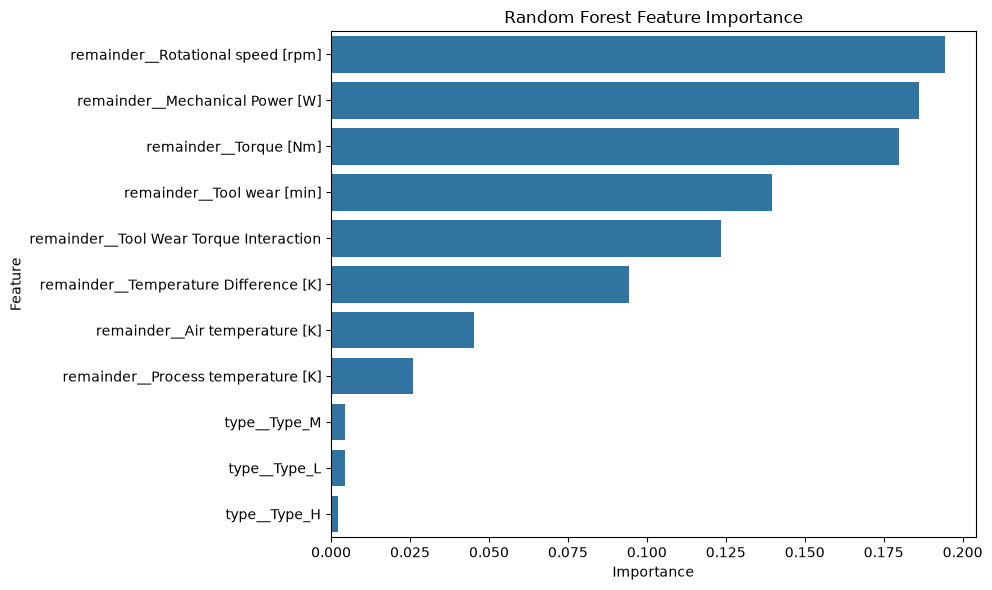

In [43]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [44]:
original_features = [
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

X_original = df[original_features].copy()

X_original_train, X_original_test, y_original_train, y_original_test = train_test_split(
    X_original,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Original training shape:", X_original_train.shape)
print("Original testing shape:", X_original_test.shape)

Original training shape: (8000, 6)
Original testing shape: (2000, 6)


In [45]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

original_preprocessor = ColumnTransformer(
    transformers=[
        (
            "type",
            OneHotEncoder(handle_unknown="ignore"),
            ["Type"]
        )
    ],
    remainder="passthrough"
)

X_original_train_processed = original_preprocessor.fit_transform(
    X_original_train
)

X_original_test_processed = original_preprocessor.transform(
    X_original_test
)

print(
    "Original processed training shape:",
    X_original_train_processed.shape
)

print(
    "Original processed testing shape:",
    X_original_test_processed.shape
)

Original processed training shape: (8000, 8)
Original processed testing shape: (2000, 8)


In [46]:
original_rf_model = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

original_rf_model.fit(
    X_original_train_processed,
    y_original_train
)

print("Original-feature Random Forest trained successfully!")

Original-feature Random Forest trained successfully!


In [47]:
original_rf_pred = original_rf_model.predict(X_original_test_processed)
original_rf_prob = original_rf_model.predict_proba(
    X_original_test_processed
)[:, 1]

print("Original-feature Random Forest predictions generated successfully!")

Original-feature Random Forest predictions generated successfully!


In [48]:
print("Original-feature Random Forest Classification Report:")
print(
    classification_report(
        y_original_test,
        original_rf_pred,
        digits=4
    )
)

print("\nOriginal-feature Random Forest Confusion Matrix:")
print(
    confusion_matrix(
        y_original_test,
        original_rf_pred
    )
)

print(
    "\nOriginal-feature Random Forest ROC-AUC:",
    round(
        roc_auc_score(y_original_test, original_rf_prob),
        4
    )
)

print(
    "Original-feature Random Forest PR-AUC:",
    round(
        average_precision_score(
            y_original_test,
            original_rf_prob
        ),
        4
    )
)

Original-feature Random Forest Classification Report:
              precision    recall  f1-score   support

           0     0.9881    0.9896    0.9889      1932
           1     0.6923    0.6618    0.6767        68

    accuracy                         0.9785      2000
   macro avg     0.8402    0.8257    0.8328      2000
weighted avg     0.9781    0.9785    0.9783      2000


Original-feature Random Forest Confusion Matrix:
[[1912   20]
 [  23   45]]

Original-feature Random Forest ROC-AUC: 0.9699
Original-feature Random Forest PR-AUC: 0.7556


In [51]:
print([name for name in globals() if "rf" in name.lower()])

['rf_pred', 'rf_prob', 'original_rf_model', 'original_rf_pred', 'original_rf_prob']


In [52]:
from sklearn.base import BaseEstimator

models_in_memory = {
    name: type(value).__name__
    for name, value in globals().items()
    if isinstance(value, BaseEstimator)
}

models_in_memory

{'preprocessor': 'ColumnTransformer',
 'logistic_model': 'LogisticRegression',
 'random_forest_model': 'RandomForestClassifier',
 'original_preprocessor': 'ColumnTransformer',
 'original_rf_model': 'RandomForestClassifier'}

In [53]:
import joblib

joblib.dump(random_forest_model, "../models/indupredict_random_forest.pkl")

print("Final Random Forest model saved successfully!")

Final Random Forest model saved successfully!
